# Module 1 · Understanding coordinates and 3D space

*Companion notebook for **Algebra Made Easy**, the algebra behind AI.*

You do not need any linear algebra for this. If you can read a Python list, you are ready.
By the end you will be able to answer the seven questions of Module 1:

1. What is a dimension?
2. What are coordinates?
3. What is an origin?
4. What is a coordinate plane?
5. What is 3D space, and what is a plane inside it?
6. What is the difference between a point and a vector?
7. How can a real-world position be written as numbers?

**How to use it:** run the cells from top to bottom (Shift + Enter). Every cell works as it is.
Cells marked **Try it** have a `TODO` you can change and re-run.

## Setup

Three libraries:

- **NumPy** stores lists of numbers as arrays and does maths on them.
- **Matplotlib** draws flat (2D) pictures.
- **Plotly** draws 3D pictures you can rotate with the mouse.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.io as pio

# Keep the notebook small: load plotly.js from the web instead of embedding it.
try:
    import google.colab  # noqa: F401
    pio.renderers.default = "colab"
except ImportError:
    pio.renderers.default = "plotly_mimetype+notebook_connected"

np.set_printoptions(suppress=True)
print("NumPy", np.__version__, "is ready")

NumPy 2.5.5 is ready


---
## 1 · Dimensions and the origin

*How many numbers does it take to say where something is?*

- A bead on a string: **1 number** (how far along). That is **1 dimension**.
- A pin on a map: **2 numbers** (across, up). **2 dimensions**.
- A fly in a room: **3 numbers** (across, up, forward). **3 dimensions**.

Those numbers are the **coordinates**. They are all measured from one agreed starting spot,
the **origin**, where every coordinate is 0.

In NumPy a position is just an array. Its `shape` tells you how many numbers it holds.

In [2]:
bead = np.array([4])            # 1D: 4 steps along the string
pin  = np.array([3, 2])         # 2D: 3 across, 2 up
fly  = np.array([3, 2, 5])      # 3D: 3 across, 2 up, 5 forward

for name, p in [("bead", bead), ("pin", pin), ("fly", fly)]:
    print(f"{name:5} {str(p):10} shape={p.shape}  -> {p.size} dimension(s)")

bead  [4]        shape=(1,)  -> 1 dimension(s)
pin   [3 2]      shape=(2,)  -> 2 dimension(s)
fly   [3 2 5]    shape=(3,)  -> 3 dimension(s)


The origin is the position made of all zeros. It has the same shape as every other position in that space.

In [3]:
origin_3d = np.zeros(3)
print("origin in 3D:", origin_3d)

origin in 3D: [0. 0. 0.]


Nothing stops at 3. We cannot *picture* 5 dimensions, but writing 5 numbers is easy.
Here is a house described by five measured features: one dimension per feature.

In [4]:
# rooms, bathrooms, area (m²), age (years), distance to station (km)
house = np.array([3, 2, 120, 15, 0.8])
print(house, "shape:", house.shape)

[  3.    2.  120.   15.    0.8] shape: (5,)


Many positions at once? Stack them as **rows**. The shape becomes *(rows, dimensions)*.

In [5]:
houses = np.array([
    [3, 2, 120, 15, 0.8],
    [2, 1,  70, 40, 2.5],
    [4, 3, 160,  5, 5.0],
])
print("shape:", houses.shape, "-> 3 houses, 5 dimensions each")

shape: (3, 5) -> 3 houses, 5 dimensions each


### Try it

Describe **your phone** with four numbers you could measure (e.g. price, weight in grams,
screen size, battery hours). Run the cell and check the shape says `(4,)`.

In [6]:
# TODO: replace these four numbers with your own phone's
my_phone = np.array([500, 180, 6.1, 20])
print(my_phone, "shape:", my_phone.shape)

[500.  180.    6.1  20. ] shape: (4,)


> **Why an AI engineer cares:** every piece of data an AI model sees has a number of dimensions: one per measured feature.

---
## 2 · The coordinate plane

*Points, axes, quadrants and (x, y).*

Two number lines crossed at the origin make a **coordinate plane**:

- the **x-axis** runs left (negative) to right (positive);
- the **y-axis** runs down (negative) to up (positive).

A point is written **(x, y)**: first go across, then go up. The axes cut the plane into four
**quadrants**, numbered I to IV anticlockwise from top-right.

In [7]:
points = {"A": (3, 2), "B": (-2, 3), "C": (-3, -1), "D": (2, -3), "E": (0, 0)}

def quadrant(x, y):
    if x == 0 or y == 0:
        return "on an axis"
    if x > 0:
        return "I" if y > 0 else "IV"
    return "II" if y > 0 else "III"

print("point    x    y   quadrant")
for name, (x, y) in points.items():
    print(f"  {name}   {x:4} {y:4}   {quadrant(x, y)}")

point    x    y   quadrant
  A      3    2   I
  B     -2    3   II
  C     -3   -1   III
  D      2   -3   IV
  E      0    0   on an axis


Now draw them. We move Matplotlib's axes so they cross at the origin, like a school graph.

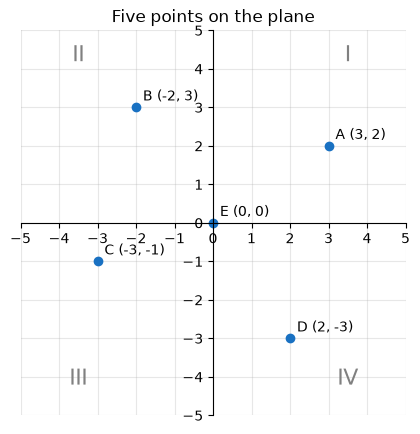

In [8]:
def school_axes(ax, lim=5):
    # Axes through the origin, a light grid and equal scaling.
    ax.spines[["left", "bottom"]].set_position("zero")
    ax.spines[["right", "top"]].set_visible(False)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xticks(range(-lim, lim + 1)); ax.set_yticks(range(-lim, lim + 1))
    ax.grid(alpha=0.3)
    ax.set_aspect("equal")

fig, ax = plt.subplots(figsize=(5, 5))
school_axes(ax)
for label, (qx, qy) in {"I": (3.5, 4.2), "II": (-3.5, 4.2), "III": (-3.5, -4.2), "IV": (3.5, -4.2)}.items():
    ax.text(qx, qy, label, fontsize=16, color="grey", ha="center")
for name, (x, y) in points.items():
    ax.plot(x, y, "o", color="#1971c2")
    ax.annotate(f"{name} ({x}, {y})", (x, y), textcoords="offset points", xytext=(5, 5))
ax.set_title("Five points on the plane")
plt.show()

### A two-feature dataset

Each email below is described by **two numbers**: how many links it has (x) and how many "!" marks (y).
So each email is a point on the plane, and spam lands in a different region from normal mail.

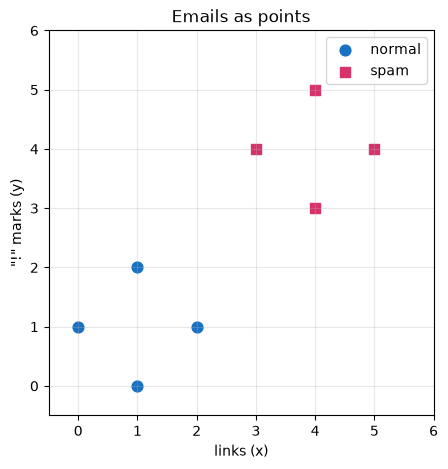

In [9]:
normal = np.array([[1, 0], [0, 1], [1, 2], [2, 1]])
spam   = np.array([[4, 3], [3, 4], [5, 4], [4, 5]])

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(normal[:, 0], normal[:, 1], color="#1971c2", label="normal", s=60)
ax.scatter(spam[:, 0], spam[:, 1], color="#d6336c", label="spam", s=60, marker="s")
ax.set_xlabel("links (x)"); ax.set_ylabel('"!" marks (y)')
ax.set_xlim(-0.5, 6); ax.set_ylim(-0.5, 6); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.legend(); ax.set_title("Emails as points")
plt.show()

### Try it

Add a point **F** in quadrant III and a point **G** exactly on the y-axis.
Re-run this cell and check the printed quadrants.

In [10]:
# TODO: change F and G
my_points = {"F": (1, 1), "G": (2, 2)}
for name, (x, y) in my_points.items():
    print(name, (x, y), "->", quadrant(x, y))

F (1, 1) -> I
G (2, 2) -> I


> **Why an AI engineer cares:** a data example with two measured features is a point on this plane.

---
## 3 · 3D space: the room

*Width, height, depth, and flat planes inside space.*

Stand in the corner of a room. That corner is the origin. Three edges leave it:
along the floor (**x**), along the other floor edge (**y**), and up the wall (**z**).
Any spot in the room is **(x, y, z)**.

The plot below is interactive: drag to rotate, scroll to zoom. The dashed line under each point
drops straight to the floor: its **shadow** is the 2D point (x, y) with z set to 0.

In [11]:
P = np.array([
    [1, 1, 3],
    [3, 1, 1],
    [2, 3, 4],
    [4, 4, 2],
])
labels = ["P1", "P2", "P3", "P4"]

shadows = P.copy()
shadows[:, 2] = 0          # same x and y, height 0
print(shadows)

[[1 1 0]
 [3 1 0]
 [2 3 0]
 [4 4 0]]


In [12]:
fig = go.Figure()
for p, s in zip(P, shadows):
    fig.add_trace(go.Scatter3d(x=[p[0], s[0]], y=[p[1], s[1]], z=[p[2], s[2]],
                               mode="lines", line=dict(color="grey", dash="dash"), showlegend=False))
fig.add_trace(go.Scatter3d(x=shadows[:, 0], y=shadows[:, 1], z=shadows[:, 2], mode="markers",
                           marker=dict(size=4, color="lightgrey"), name="shadow on the floor"))
fig.add_trace(go.Scatter3d(x=P[:, 0], y=P[:, 1], z=P[:, 2], mode="markers+text", text=labels,
                           marker=dict(size=6, color="#1971c2"), name="points"))
fig.update_layout(width=550, height=450, margin=dict(l=0, r=0, t=30, b=0),
                  title="Points in a room and their shadows",
                  scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z (height)"))
fig.show()

### A plane inside space

A **plane** is a flat sheet that goes on forever, like a tilted tabletop. In 3D, a plane cuts space
into **two sides**. Here is the tilted plane `z = 0.5·x + 0.5·y`. For each point we compare its height with the
plane's height right below or above it: the sign tells us which side the point is on.

In [13]:
def plane_height(x, y):
    return 0.5 * x + 0.5 * y

side = np.sign(P[:, 2] - plane_height(P[:, 0], P[:, 1]))
for name, p, s in zip(labels, P, side):
    print(name, p, "above the plane" if s > 0 else "below the plane" if s < 0 else "on the plane")

P1 [1 1 3] above the plane
P2 [3 1 1] below the plane
P3 [2 3 4] above the plane
P4 [4 4 2] below the plane


In [14]:
gx, gy = np.meshgrid(np.linspace(0, 5, 10), np.linspace(0, 5, 10))
colors = np.where(side > 0, "#2b8a3e", "#e8590c")

fig = go.Figure()
fig.add_trace(go.Surface(x=gx, y=gy, z=plane_height(gx, gy), opacity=0.5,
                         colorscale=[[0, "#91a7ff"], [1, "#91a7ff"]], showscale=False, name="plane"))
fig.add_trace(go.Scatter3d(x=P[:, 0], y=P[:, 1], z=P[:, 2], mode="markers+text", text=labels,
                           marker=dict(size=6, color=colors), name="points"))
fig.update_layout(width=550, height=450, margin=dict(l=0, r=0, t=30, b=0),
                  title="Green: above the plane · orange: below",
                  scene=dict(xaxis_title="x", yaxis_title="y", zaxis_title="z"))
fig.show()

### Try it

Change the plane so it is **flat** at height 2 (every point on it has z = 2).
Which points are above it now?

In [15]:
# TODO: make the plane flat at height 2, e.g. return 2 + 0 * x
def my_plane(x, y):
    return 0.5 * x + 0.5 * y

print(np.sign(P[:, 2] - my_plane(P[:, 0], P[:, 1])))

[ 1. -1.  1. -1.]


> **Why an AI engineer cares:** three features need three axes; real data uses hundreds, with exactly the same rules.
> (A plane that splits data into two sides is exactly what a simple classifier learns.)

---
## 4 · Points and vectors

*A place versus a movement: same numbers, different meaning.*

- A **point** is a *place*: "the café is at (4, 3)".
- A **vector** is a *movement*: "walk 3 right and 1 up", written (3, 1). It has no fixed starting place.

Two rules connect them:

- **point − point = vector**: `B − A` is the trip from A to B.
- **point + vector = point**: `A + v` is where you land after making the trip v from A.

In [16]:
A = np.array([1, 1])
B = np.array([4, 3])

v = B - A
print("trip from A to B:  v = B - A =", v)
print("check: A + v =", A + v, "(that is B)")

trip from A to B:  v = B - A = [3 2]
check: A + v = [4 3] (that is B)


Matplotlib's `quiver` draws arrows. `angles="xy", scale_units="xy", scale=1` makes an arrow
of (3, 2) really cover 3 across and 2 up.

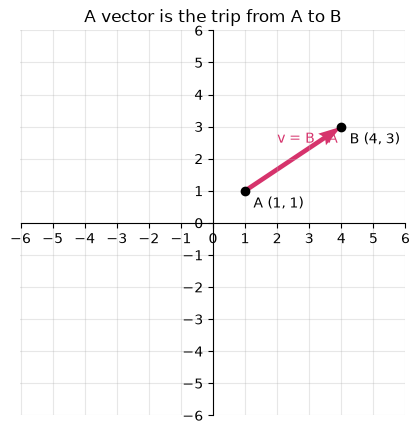

In [17]:
fig, ax = plt.subplots(figsize=(5, 5))
school_axes(ax, lim=6)
ax.quiver(*A, *v, angles="xy", scale_units="xy", scale=1, color="#d6336c", width=0.012)
for name, p in [("A", A), ("B", B)]:
    ax.plot(*p, "ko")
    ax.annotate(f"{name} {tuple(int(c) for c in p)}", p, textcoords="offset points", xytext=(6, -12))
ax.text(2.0, 2.5, "v = B - A", color="#d6336c")
ax.set_title("A vector is the trip from A to B")
plt.show()

The **same vector** can start anywhere. Below, v = (3, 2) is drawn from A and from a different point C.
Same direction, same length, same numbers: it is the same movement.

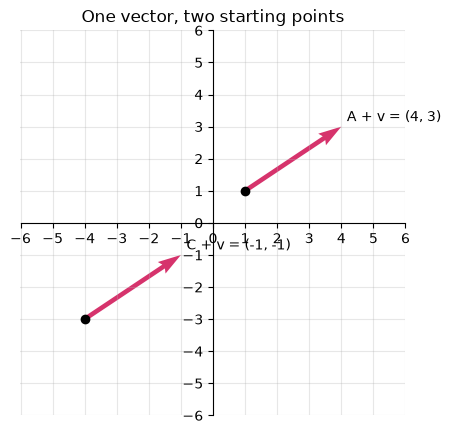

In [18]:
C = np.array([-4, -3])
starts = np.array([A, C])

fig, ax = plt.subplots(figsize=(5, 5))
school_axes(ax, lim=6)
ax.quiver(starts[:, 0], starts[:, 1], [v[0]] * 2, [v[1]] * 2,
          angles="xy", scale_units="xy", scale=1, color="#d6336c", width=0.012)
for name, p in [("A", A), ("C", C)]:
    ax.plot(*p, "ko")
    ax.annotate(f"{name} + v = {tuple(int(c) for c in p + v)}", p + v, textcoords="offset points", xytext=(4, 4))
ax.set_title("One vector, two starting points")
plt.show()

### Try it

Start at A = (1, 1). Make a vector `w` that lands you exactly on the origin. Then check `A + w`.

In [19]:
# TODO: choose w so that A + w == (0, 0)
w = np.array([0, 0])
print("A + w =", A + w)

A + w = [1 1]


> **Why an AI engineer cares:** embeddings, gradients and model updates are all vectors: movements in feature space.

---
## 5 · Positions in the real world

*Choose an origin, axes and units, and anything has an address.*

Coordinates only mean something once three choices are made:

1. **an origin** (where is zero?),
2. **axes** (which directions count as x, y, z?),
3. **units** (metres? centimetres? steps?).

Change any of them and the numbers change, even though nothing in the world moved.

### Moving the origin

Three places in a town, measured in metres from the town hall. Now we decide the **station**
should be the origin instead. Every new position is `old position − new origin`.

In [20]:
places = np.array([
    [0,    0],     # town hall
    [300, 400],    # station
    [-200, 100],   # school
])
names = ["town hall", "station", "school"]

station = places[1]
from_station = places - station   # NumPy subtracts the station from every row

for n, old, new in zip(names, places, from_station):
    print(f"{n:10} from town hall: {str(old):12} from station: {new}")

town hall  from town hall: [0 0]        from station: [-300 -400]
station    from town hall: [300 400]    from station: [0 0]
school     from town hall: [-200  100]  from station: [-500 -300]


Same three places, two different sets of numbers. The *gaps* between places are unchanged:

In [21]:
print("school - station, old numbers:", places[2] - places[1])
print("school - station, new numbers:", from_station[2] - from_station[1])

school - station, old numbers: [-500 -300]
school - station, new numbers: [-500 -300]


### Changing the units

Switching from metres to kilometres divides every coordinate by 1000. The places stay put;
only the numbers shrink.

In [22]:
in_km = from_station / 1000
print(in_km)

[[-0.3 -0.4]
 [ 0.   0. ]
 [-0.5 -0.3]]


### A gentle data example: fruit as points

Measure each fruit with three numbers: **weight** (grams), **sweetness** (0 to 10) and **sourness** (0 to 10).
Each fruit becomes a point in 3D space. Similar fruits land close together.

In [23]:
fruit = {
    "apple":  np.array([[180, 7, 3], [200, 8, 2], [160, 6, 3]]),
    "lemon":  np.array([[100, 2, 9], [120, 1, 8], [ 90, 2, 9]]),
    "banana": np.array([[120, 9, 1], [130, 8, 1], [110, 9, 2]]),
}
fruit_color = {"apple": "#d6336c", "lemon": "#f59f00", "banana": "#2b8a3e"}

X = np.vstack(list(fruit.values()))
print("all fruit as one array, shape:", X.shape, "-> 9 fruits, 3 features each")

all fruit as one array, shape: (9, 3) -> 9 fruits, 3 features each


In [24]:
fig = go.Figure()
for kind, pts in fruit.items():
    fig.add_trace(go.Scatter3d(x=pts[:, 0], y=pts[:, 1], z=pts[:, 2], mode="markers", name=kind,
                               marker=dict(size=6, color=fruit_color[kind])))
fig.update_layout(width=550, height=450, margin=dict(l=0, r=0, t=30, b=0),
                  title="Fruit in feature space",
                  scene=dict(xaxis_title="weight (g)", yaxis_title="sweetness", zaxis_title="sourness"))
fig.show()

Units matter here too: weight runs into the hundreds while the scores stay below 10, so weight dominates
any distance. Picking the origin at the *average fruit* is a common first step in AI (called **centring**):

In [25]:
average_fruit = X.mean(axis=0)
centred = X - average_fruit        # same idea as "positions - new_origin"
print("average fruit:", average_fruit.round(1))
print("first three fruits, centred:\n", centred[:3].round(1))

average fruit: [134.4   5.8   4.2]
first three fruits, centred:
 [[45.6  1.2 -1.2]
 [65.6  2.2 -2.2]
 [25.6  0.2 -1.2]]


### Try it

1. Make the **school** the origin instead of the station (`places - places[2]`).
2. Add a fourth fruit kind of your own (e.g. `"grape"`) to `fruit` and `fruit_color`, then re-run the Plotly cell.

In [26]:
# TODO: make the school the origin
new_origin = places[1]
print(places - new_origin)

[[-300 -400]
 [   0    0]
 [-500 -300]]


> **Why an AI engineer cares:** turning real things into lists of numbers is the first step of every AI project.

---
## Recap

| Idea | In NumPy |
|---|---|
| dimension = how many numbers per position | `p.shape`, `X.shape[1]` |
| origin = all zeros | `np.zeros(n)` |
| point vs vector | `B - A` is a vector, `A + v` is a point |
| new origin | `positions - new_origin` |
| new units | `positions / 1000` |

Next up, **Module 2** builds the school-algebra toolkit the rest of the course leans on.